Shape of the digits dataset: (1797, 64)


Text(0.5, 1.0, 'Digit: 0')

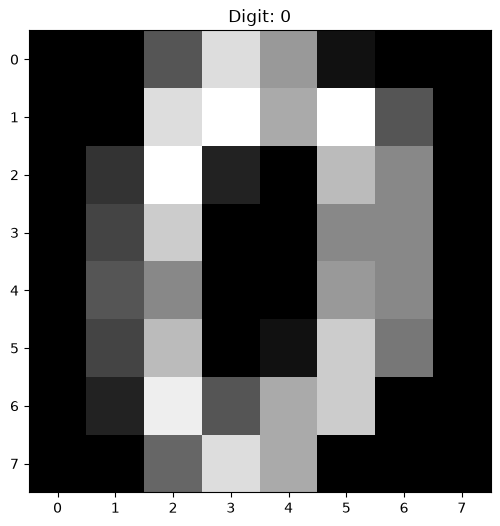

In [3]:
from sklearn.datasets import load_digits
import matplotlib.pyplot as plt
digits = load_digits()

data = digits.data
print(f"Shape of the digits dataset: {data.shape}")

plt.figure(figsize=(8, 6))
plt.imshow(digits.images[0], cmap='gray')
plt.title(f"Digit: {digits.target[0]}")

In [5]:
from sklearn.decomposition import PCA
pca = PCA(n_components=10)
data_reduced = pca.fit_transform(data)
print(f"Shape of the reduced data: {data_reduced.shape}")

Shape of the reduced data: (1797, 10)


In [6]:
data_reconstructed = pca.inverse_transform(data_reduced)
print(f"Shape of the reconstructed data: {data_reconstructed.shape}")


Shape of the reconstructed data: (1797, 64)


Text(0.5, 1.0, 'Reconstructed Image')

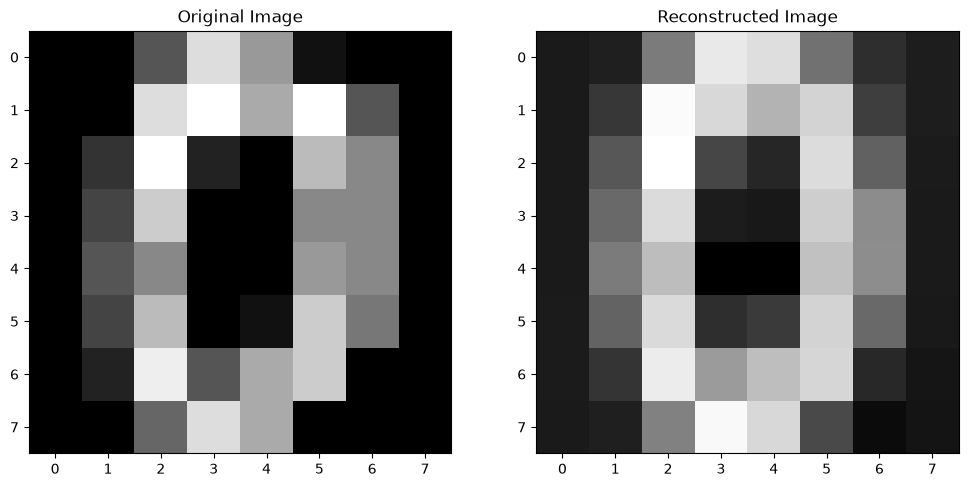

In [7]:
first_image = data[0].reshape(8, 8)
first_image_reconstructed = data_reconstructed[0].reshape(8, 8)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(first_image, cmap='gray')
plt.title("Original Image") 

plt.subplot(1, 2, 2)
plt.imshow(first_image_reconstructed, cmap='gray')
plt.title("Reconstructed Image")


Explained Variance Ratio with 2 components: 28.51%
Explained Variance Ratio with 5 components: 54.50%
Explained Variance Ratio with 10 components: 73.82%
Explained Variance Ratio with 20 components: 89.43%
Explained Variance Ratio with 40 components: 98.82%
Seuil de 90 % atteint
Explained Variance Ratio with 64 components: 100.00%
Seuil de 90 % atteint


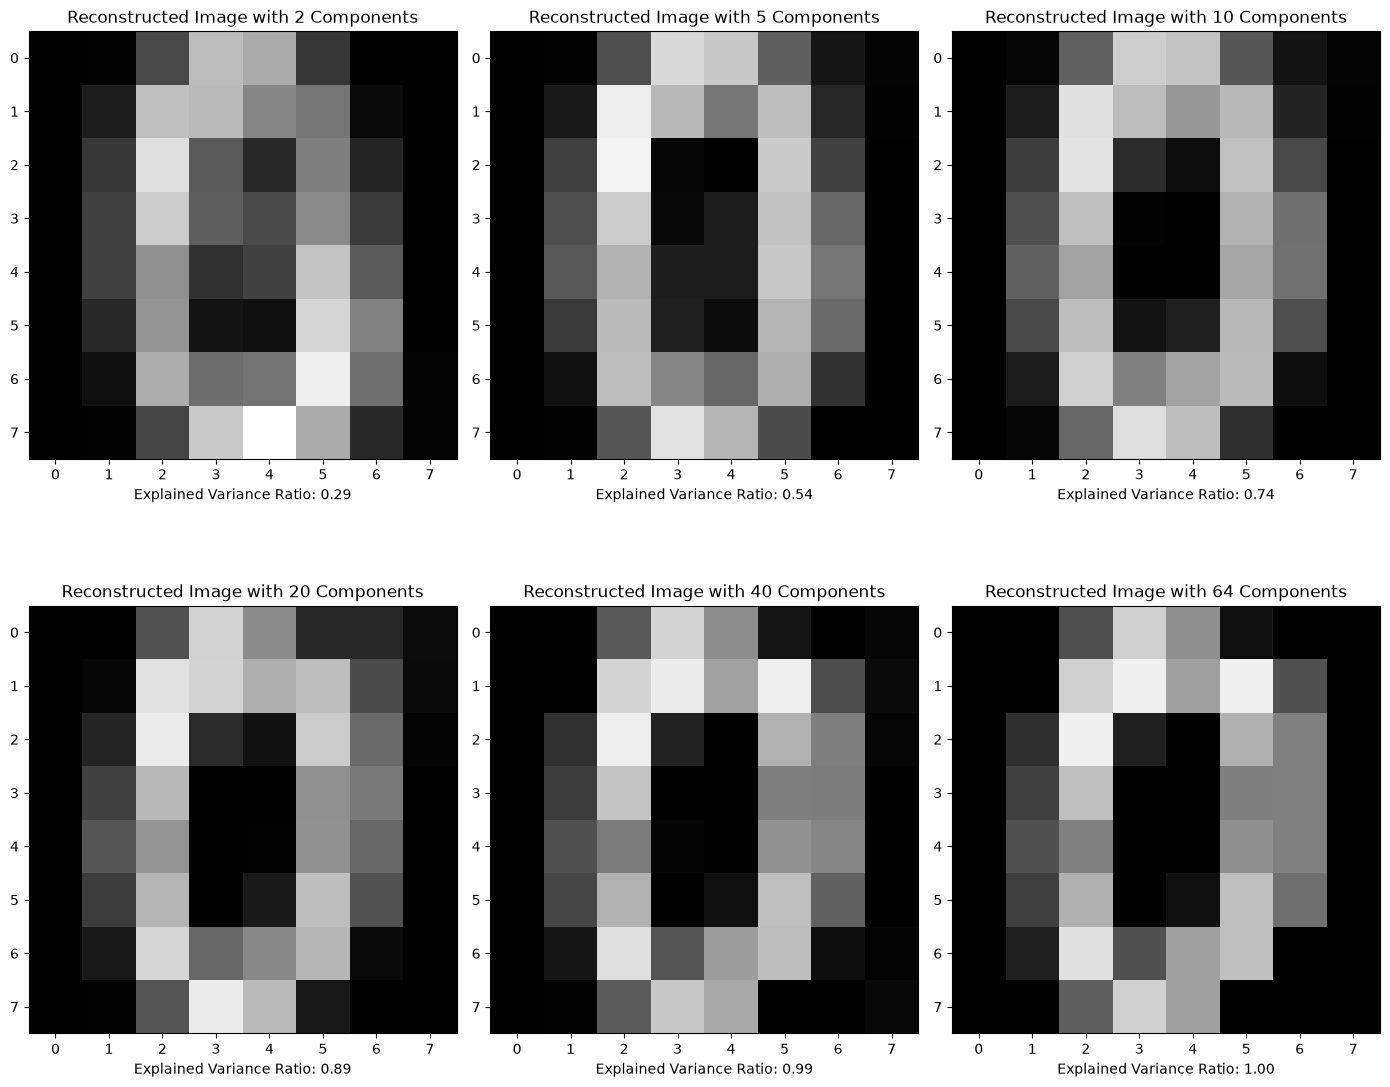

In [ ]:
seuil_trouve = False
plt.figure(figsize=(14, 12))
for position, i in enumerate([2,5,10,20,40,64]):
    pca = PCA(n_components=i)
    data_reduced = pca.fit_transform(data)
    data_reconstructed = pca.inverse_transform(data_reduced)
    
    first_image_reconstructed = data_reconstructed[0].reshape(8, 8)
    explained_variance_ratio = pca.explained_variance_ratio_.sum()
    print(f"Explained Variance Ratio with {i} components: {explained_variance_ratio * 100:.2f}%")
    if explained_variance_ratio >= 0.90:
        print("Seuil de 90 % atteint")
    plt.subplot(2, 3, position + 1)
    plt.imshow(first_image_reconstructed, cmap='gray',vmin=0, vmax=16)
    plt.title(f"Reconstructed Image with {i} Components")
    plt.xlabel(f"Explained Variance Ratio: {explained_variance_ratio:.2f}")
plt.tight_layout()
plt.show()
